In [1]:
!pip install -q lightning pytorch-forecasting optuna shap scikit-learn openpyxl

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.3/425.3 kB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 40.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 27.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.3/165.3 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 67.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 61.4 MB/s eta 0:00:00


In [2]:
import os, gc, json, random, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import lightning.pytorch as pl
from lightning.pytorch.callbacks import EarlyStopping
from pytorch_forecasting import TimeSeriesDataSet, TemporalFusionTransformer
from pytorch_forecasting.data import GroupNormalizer
from pytorch_forecasting.metrics import QuantileLoss
import optuna

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import r2_score
import shap

from google.colab import drive
drive.mount("/content/drive", force_remount=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
pl.seed_everything(SEED, workers=True)

BASE_DIR = Path("/content/drive/MyDrive")
SALES_FILE = BASE_DIR / "model_ready_category_dataset.csv"
OUTPUT_DIR = BASE_DIR / "model_6_1_tft_only_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATE_COL = "week_start"
CATEGORY_COL = "Product Category"
TARGET_COL = "weekly_quantity"

SEASONAL_PERIOD = 52
MAX_HORIZON = 12
FORECAST_HORIZONS = [4, 8, 12]
OUTER_ORIGINS = {
    "spring_2025": "2025-04-07",
    "summer_2025": "2025-07-07",
    "early_autumn_2025": "2025-09-08",
    "q4_year_end_2025": "2025-10-06",
}

TUNING_HORIZON = 12
TUNING_OFFSETS_WEEKS = [36, 24, 12]
N_TRIALS = 30
TUNING_MAX_EPOCHS = 30
EPS = 1e-12

print("Input:", SALES_FILE)
print("Output:", OUTPUT_DIR)

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42


Mounted at /content/drive
Input: /content/drive/MyDrive/model_ready_category_dataset.csv
Output: /content/drive/MyDrive/model_6_1_tft_only_outputs


In [3]:
if not SALES_FILE.exists():
    raise FileNotFoundError(SALES_FILE)

raw = pd.read_csv(SALES_FILE)
raw.columns = [c.strip() for c in raw.columns]
required = [CATEGORY_COL, DATE_COL, TARGET_COL]
missing = [c for c in required if c not in raw.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

raw = raw[required].copy()
raw[DATE_COL] = pd.to_datetime(raw[DATE_COL], errors="coerce")
raw[TARGET_COL] = pd.to_numeric(raw[TARGET_COL], errors="coerce")
raw = raw.dropna(subset=required)
raw[CATEGORY_COL] = raw[CATEGORY_COL].astype(str).str.strip()
raw[TARGET_COL] = raw[TARGET_COL].clip(lower=0)

if raw.duplicated([CATEGORY_COL, DATE_COL]).any():
    raise ValueError("Duplicate category-week observations detected.")

categories = sorted(raw[CATEGORY_COL].unique())
dataset_min, dataset_max = raw[DATE_COL].min(), raw[DATE_COL].max()
all_weeks = pd.date_range(dataset_min, dataset_max, freq="W-MON")
panel_index = pd.MultiIndex.from_product([categories, all_weeks], names=[CATEGORY_COL, DATE_COL])
weekly = raw.set_index([CATEGORY_COL, DATE_COL]).reindex(panel_index).reset_index()
weekly[TARGET_COL] = weekly[TARGET_COL].fillna(0.0).clip(lower=0)
weekly = weekly.rename(columns={DATE_COL: "week", TARGET_COL: "target"})
weekly["series_id"] = weekly[CATEGORY_COL].astype(str)
weekly = weekly.sort_values(["series_id", "week"]).reset_index(drop=True)

week_to_idx = {w: i for i, w in enumerate(sorted(weekly["week"].unique()))}
weekly["time_idx"] = weekly["week"].map(week_to_idx).astype(int)
weekly["month"] = weekly["week"].dt.month.astype(float)
weekly["quarter"] = weekly["week"].dt.quarter.astype(float)
weekly["week_of_year"] = weekly["week"].dt.isocalendar().week.astype(float)
weekly["week_sin"] = np.sin(2*np.pi*weekly["week_of_year"]/52.0)
weekly["week_cos"] = np.cos(2*np.pi*weekly["week_of_year"]/52.0)
weekly["month_sin"] = np.sin(2*np.pi*weekly["month"]/12.0)
weekly["month_cos"] = np.cos(2*np.pi*weekly["month"]/12.0)

weekly["seasonal_lag_52"] = weekly.groupby("series_id")["target"].shift(52)
weekly["seasonal_lag_52_available"] = weekly["seasonal_lag_52"].notna().astype(float)
weekly["seasonal_lag_52"] = weekly["seasonal_lag_52"].fillna(0.0)

print("Shape:", weekly.shape)
print("Categories:", weekly["series_id"].nunique())
print("Date range:", weekly["week"].min().date(), "to", weekly["week"].max().date())
print("Google Trends columns:", [c for c in weekly.columns if "trend" in c.lower() or "google" in c.lower()])
display(weekly.head())
weekly.to_csv(OUTPUT_DIR / "model_6_1_dataset.csv", index=False, encoding="utf-8-sig")

Shape: (6200, 14)
Categories: 40
Date range: 2023-01-09 to 2025-12-22
Google Trends columns: []


,Product Category,week,target,series_id,time_idx,month,quarter,week_of_year,week_sin,week_cos,month_sin,month_cos,seasonal_lag_52,seasonal_lag_52_available
0,AΜΠΙΓΙΕ,2023-01-09,9.0,AΜΠΙΓΙΕ,0,1.0,1.0,2.0,0.239316,0.970942,0.500000,0.866025,0.0,0.0
1,AΜΠΙΓΙΕ,2023-01-16,5.0,AΜΠΙΓΙΕ,1,1.0,1.0,3.0,0.354605,0.935016,0.500000,0.866025,0.0,0.0
2,AΜΠΙΓΙΕ,2023-01-23,153.0,AΜΠΙΓΙΕ,2,1.0,1.0,4.0,0.464723,0.885456,0.500000,0.866025,0.0,0.0
3,AΜΠΙΓΙΕ,2023-01-30,87.0,AΜΠΙΓΙΕ,3,1.0,1.0,5.0,0.568065,0.822984,0.500000,0.866025,0.0,0.0
4,AΜΠΙΓΙΕ,2023-02-06,139.0,AΜΠΙΓΙΕ,4,2.0,1.0,6.0,0.663123,0.748511,0.866025,0.500000,0.0,0.0


In [4]:
scenario_rows = []
for label, origin_s in OUTER_ORIGINS.items():
    origin = pd.Timestamp(origin_s)
    for h in FORECAST_HORIZONS:
        dates = pd.date_range(origin, periods=h, freq="W-MON")
        if dates[-1] > dataset_max:
            raise ValueError(f"{label}, h={h} exceeds dataset end")
        scenario_rows.append({
            "scenario_id": f"{label}_h{h}",
            "outer_origin_label": label,
            "outer_origin": origin,
            "horizon_weeks": h,
            "test_start": dates[0],
            "test_end": dates[-1],
        })
scenarios = pd.DataFrame(scenario_rows)
display(scenarios)
scenarios.to_csv(OUTPUT_DIR / "model_6_1_common_rolling_origin_scenarios.csv", index=False)

def mae(a, p):
    a, p = np.asarray(a, float), np.asarray(p, float)
    return float(np.mean(np.abs(a-p)))

def rmse(a, p):
    a, p = np.asarray(a, float), np.asarray(p, float)
    return float(np.sqrt(np.mean((a-p)**2)))

def mape(a, p):
    a, p = np.asarray(a, float), np.asarray(p, float)
    mask = np.abs(a) > EPS
    return np.nan if mask.sum() == 0 else float(np.mean(np.abs((a[mask]-p[mask])/a[mask]))*100)

def smape(a, p):
    a, p = np.asarray(a, float), np.asarray(p, float)
    d = np.abs(a) + np.abs(p)
    return float(np.mean(np.where(d > EPS, 2*np.abs(a-p)/d, 0))*100)

def mase_scale_info(y_train, m=52):
    y = np.asarray(y_train, float)
    if len(y) <= m:
        return np.nan, "insufficient_history"
    scale = float(np.mean(np.abs(y[m:] - y[:-m])))
    if not np.isfinite(scale):
        return np.nan, "non_finite_scale"
    if scale <= EPS:
        return np.nan, "zero_seasonal_scale"
    return scale, "valid"

def evaluate(a, p, y_train, m=52):
    scale, status = mase_scale_info(y_train, m)
    return {
        "MAE": mae(a,p), "RMSE": rmse(a,p), "MAPE": mape(a,p),
        "MAPE_N": int(np.sum(np.abs(np.asarray(a,float)) > EPS)),
        "sMAPE": smape(a,p),
        "MASE": np.nan if not np.isfinite(scale) else mae(a,p)/scale,
        "MASE_scale": scale, "MASE_status": status,
    }

print("MASE seasonal period:", SEASONAL_PERIOD)

,scenario_id,outer_origin_label,outer_origin,horizon_weeks,test_start,test_end
0,spring_2025_h4,spring_2025,2025-04-07,4,2025-04-07,2025-04-28
1,spring_2025_h8,spring_2025,2025-04-07,8,2025-04-07,2025-05-26
2,spring_2025_h12,spring_2025,2025-04-07,12,2025-04-07,2025-06-23
3,summer_2025_h4,summer_2025,2025-07-07,4,2025-07-07,2025-07-28
4,summer_2025_h8,summer_2025,2025-07-07,8,2025-07-07,2025-08-25
5,summer_2025_h12,summer_2025,2025-07-07,12,2025-07-07,2025-09-22
6,early_autumn_2025_h4,early_autumn_2025,2025-09-08,4,2025-09-08,2025-09-29
7,early_autumn_2025_h8,early_autumn_2025,2025-09-08,8,2025-09-08,2025-10-27
8,early_autumn_2025_h12,early_autumn_2025,2025-09-08,12,2025-09-08,2025-11-24
9,q4_year_end_2025_h4,q4_year_end_2025,2025-10-06,4,2025-10-06,2025-10-27


MASE seasonal period: 52


In [5]:
CALENDAR_FEATURE_SETS = {
    "cyclical": ["time_idx", "week_sin", "week_cos", "month_sin", "month_cos"],
    "full": ["time_idx", "month", "quarter", "week_of_year", "week_sin", "week_cos", "month_sin", "month_cos"],
}
STATIC_CATEGORICALS = ["series_id"]
UNKNOWN_REALS = ["target"]
SEASONAL_KNOWN_REALS = ["seasonal_lag_52", "seasonal_lag_52_available"]

def known_reals_for(feature_set):
    return CALENDAR_FEATURE_SETS[feature_set] + SEASONAL_KNOWN_REALS

def make_training_dataset(train_df, prediction_length, encoder_length, feature_set):
    return TimeSeriesDataSet(
        train_df.copy(),
        time_idx="time_idx",
        target="target",
        group_ids=["series_id"],
        min_encoder_length=max(26, min(encoder_length, 39)),
        max_encoder_length=encoder_length,
        min_prediction_length=prediction_length,
        max_prediction_length=prediction_length,
        static_categoricals=STATIC_CATEGORICALS,
        time_varying_known_reals=known_reals_for(feature_set),
        time_varying_unknown_reals=UNKNOWN_REALS,
        target_normalizer=GroupNormalizer(groups=["series_id"], transformation="softplus"),
        add_relative_time_idx=True,
        add_target_scales=True,
        add_encoder_length=True,
        allow_missing_timesteps=False,
    )

def validation_dataset_from_training(training_ds, data_through_validation):
    return TimeSeriesDataSet.from_dataset(
        training_ds, data_through_validation, predict=True, stop_randomization=True
    )

def prediction_frame(origin, encoder_length, horizon=12):
    origin = pd.Timestamp(origin)
    enc = weekly[weekly["week"] < origin].groupby("series_id", group_keys=False).tail(encoder_length).copy()
    future = weekly[(weekly["week"] >= origin) & (weekly["week"] < origin + pd.Timedelta(weeks=horizon))].copy()
    if future.groupby("series_id").size().min() != horizon:
        raise ValueError("Incomplete future calendar frame.")

    future["target"] = 0.0
    return pd.concat([enc, future], ignore_index=True).sort_values(["series_id", "time_idx"])

def extract_predictions(model, loader):
    out = model.predict(loader, mode="prediction", return_index=True)
    if hasattr(out, "output"):
        pred, idx = out.output, out.index.copy()
    else:
        pred, idx = out[0], out[1].copy()
    pred = pred.detach().cpu().numpy() if torch.is_tensor(pred) else np.asarray(pred)
    return pred, idx

[I 2026-10-04 12:26:38,421] A new study created in memory with name: model_6_1_tft_only


Architecture tuning folds:
fold 1: validation 2024-07-29 to 2024-10-14
fold 2: validation 2024-10-21 to 2025-01-06
fold 3: validation 2025-01-13 to 2025-03-31


  0%|          | 0/30 [00:00<?, ?it/s]

INFO: Seed set to 43
INFO:lightning.fabric.utilities.seed:Seed set to 43
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: You are using a CUDA device ('NVIDIA L4') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | '

[I 2026-10-04 12:29:02,789] Trial 0 finished with value: 4.00273975771823 and parameters: {'encoder_length': 52, 'feature_set': 'cyclical', 'hidden_size': 32, 'attention_head_size': 2, 'dropout': 0.35, 'hidden_continuous_size': 4, 'learning_rate': 0.00036092627369616975, 'gradient_clip_val': 0.5}. Best is trial 0 with value: 4.00273975771823.


...

[I 2026-10-04 13:40:24,860] Trial 27 finished with value: 3.969241331642579 and parameters: {'encoder_length': 52, 'feature_set': 'cyclical', 'hidden_size': 8, 'attention_head_size': 4, 'dropout': 0.15000000000000002, 'hidden_continuous_size': 4, 'learning_rate': 0.0025442955997436044, 'gradient_clip_val': 0.1}. Best is trial 2 with value: 3.1738197367141248.


INFO: Seed set to 323
INFO:lightning.fabric.utilities.seed:Seed set to 323
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: GPU available: True (

[I 2026-10-04 13:42:14,327] Trial 28 finished with value: 3.9743534611482456 and parameters: {'encoder_length': 39, 'feature_set': 'cyclical', 'hidden_size': 32, 'attention_head_size': 1, 'dropout': 0.25, 'hidden_continuous_size': 8, 'learning_rate': 0.00022852714593719203, 'gradient_clip_val': 0.1}. Best is trial 2 with value: 3.1738197367141248.


INFO: Seed set to 333
INFO:lightning.fabric.utilities.seed:Seed set to 333
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: GPU available: True (

[I 2026-10-04 13:44:23,019] Trial 29 finished with value: 4.127298517558988 and parameters: {'encoder_length': 39, 'feature_set': 'cyclical', 'hidden_size': 32, 'attention_head_size': 1, 'dropout': 0.25, 'hidden_continuous_size': 8, 'learning_rate': 0.0006874163601902288, 'gradient_clip_val': 0.1}. Best is trial 2 with value: 3.1738197367141248.
Requested trials: 30
Best trial: 2
Best mean multi-horizon validation MASE score: 3.1738197367141248
Best architecture: {'encoder_length': 39, 'feature_set': 'cyclical', 'hidden_size': 8, 'attention_head_size': 4, 'dropout': 0.15000000000000002, 'hidden_continuous_size': 4, 'learning_rate': 0.0035640595324118764, 'gradient_clip_val': 0.5}
Final refit epochs selected from tuning: 10


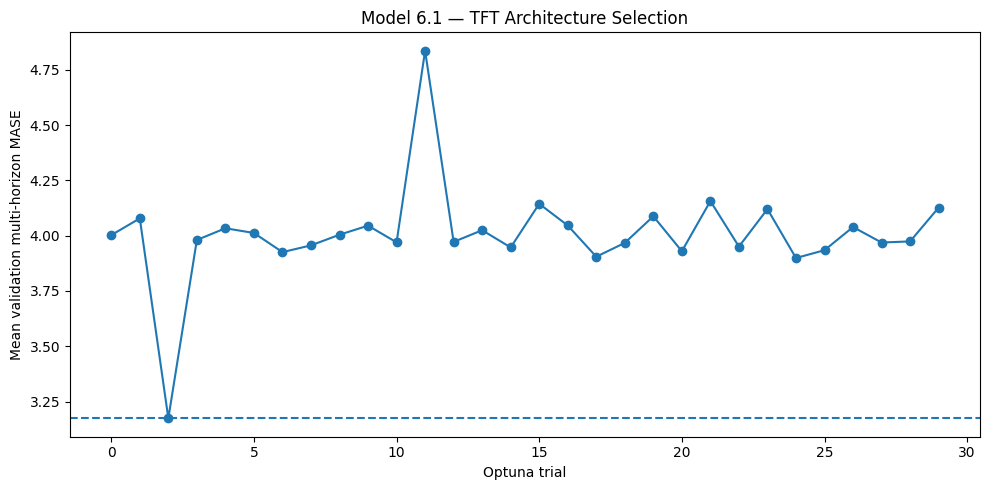

In [6]:
EARLIEST_OUTER_ORIGIN = pd.Timestamp(min(OUTER_ORIGINS.values()))

def tuning_folds_before_first_outer():
    folds = []
    for fold, off in enumerate(TUNING_OFFSETS_WEEKS, 1):
        val_origin = EARLIEST_OUTER_ORIGIN - pd.Timedelta(weeks=off)
        val_dates = pd.date_range(val_origin, periods=TUNING_HORIZON, freq="W-MON")
        assert val_dates[-1] < EARLIEST_OUTER_ORIGIN
        folds.append((fold, val_origin, val_dates))
    return folds

tuning_folds = tuning_folds_before_first_outer()
print("Architecture tuning folds:")
for f, vo, vd in tuning_folds:
    print(f"fold {f}: validation {vd[0].date()} to {vd[-1].date()}")

trial_fold_records = []

def validation_mase_scores(pred_array, pred_index, val_origin, train_df):
    rows = []
    idx = pred_index.reset_index(drop=True)
    for i, row in idx.iterrows():
        cat = str(row["series_id"])
        p = np.maximum(np.asarray(pred_array[i], float).reshape(-1)[:TUNING_HORIZON], 0.0)
        actual = weekly[(weekly["series_id"] == cat) & (weekly["week"] >= val_origin)].sort_values("week").head(TUNING_HORIZON)
        if len(actual) != TUNING_HORIZON or len(p) != TUNING_HORIZON:
            continue
        a = actual["target"].to_numpy(float)
        hist = train_df[train_df["series_id"] == cat].sort_values("week")["target"].to_numpy(float)
        for h in FORECAST_HORIZONS:
            met = evaluate(a[:h], p[:h], hist, SEASONAL_PERIOD)
            rows.append({"category": cat, "horizon": h, **met})
    return pd.DataFrame(rows)

def objective(trial):
    params = {
        "encoder_length": trial.suggest_categorical("encoder_length", [39, 52, 78]),
        "feature_set": trial.suggest_categorical("feature_set", ["cyclical", "full"]),
        "hidden_size": trial.suggest_categorical("hidden_size", [8, 16, 32]),
        "attention_head_size": trial.suggest_categorical("attention_head_size", [1, 2, 4]),
        "dropout": trial.suggest_float("dropout", 0.10, 0.35, step=0.05),
        "hidden_continuous_size": trial.suggest_categorical("hidden_continuous_size", [4, 8, 16]),
        "learning_rate": trial.suggest_float("learning_rate", 2e-4, 5e-3, log=True),
        "gradient_clip_val": trial.suggest_categorical("gradient_clip_val", [0.1, 0.5, 1.0]),
    }

    fold_scores, fold_epochs = [], []
    for fold, val_origin, val_dates in tuning_folds:
        pl.seed_everything(SEED + trial.number*10 + fold, workers=True)
        train_df = weekly[weekly["week"] < val_origin].copy()
        val_through = weekly[weekly["week"] <= val_dates[-1]].copy()

        try:
            training = make_training_dataset(train_df, TUNING_HORIZON, params["encoder_length"], params["feature_set"])
            validation = validation_dataset_from_training(training, val_through)
            train_loader = training.to_dataloader(train=True, batch_size=64, num_workers=0)
            val_loader = validation.to_dataloader(train=False, batch_size=64, num_workers=0)

            early = EarlyStopping(monitor="val_loss", min_delta=1e-4, patience=5, mode="min")
            trainer = pl.Trainer(
                max_epochs=TUNING_MAX_EPOCHS, accelerator="auto", devices=1,
                gradient_clip_val=params["gradient_clip_val"], callbacks=[early],
                logger=False, enable_checkpointing=False, enable_model_summary=False,
                enable_progress_bar=False,
            )
            model = TemporalFusionTransformer.from_dataset(
                training,
                learning_rate=params["learning_rate"],
                hidden_size=params["hidden_size"],
                attention_head_size=params["attention_head_size"],
                dropout=params["dropout"],
                hidden_continuous_size=params["hidden_continuous_size"],
                output_size=7,
                loss=QuantileLoss(),
                reduce_on_plateau_patience=4,
            )
            trainer.fit(model, train_loader, val_loader)
            epochs = int(trainer.current_epoch) + 1

            pred_array, pred_index = extract_predictions(model, val_loader)
            score_df = validation_mase_scores(pred_array, pred_index, val_origin, train_df)
            horizon_means = score_df.groupby("horizon")["MASE"].mean().reindex(FORECAST_HORIZONS)
            if horizon_means.notna().all():
                fold_score = float(horizon_means.mean())
            else:
                fold_score = float(score_df["sMAPE"].mean() / 100.0)

            val_loss_obj = trainer.callback_metrics.get("val_loss")
            val_loss = float(val_loss_obj.detach().cpu().item()) if val_loss_obj is not None else np.nan

            trial_fold_records.append({
                "trial": trial.number, "fold": fold,
                "validation_origin": val_origin, "validation_end": val_dates[-1],
                "cv_score": fold_score, "val_loss": val_loss, "epochs": epochs,
                "MASE_h4": horizon_means.get(4, np.nan),
                "MASE_h8": horizon_means.get(8, np.nan),
                "MASE_h12": horizon_means.get(12, np.nan),
                **params,
            })
        except Exception as e:
            print(f"Trial {trial.number}, fold {fold} failed: {e}")
            fold_score, epochs = np.inf, TUNING_MAX_EPOCHS
            trial_fold_records.append({
                "trial": trial.number, "fold": fold,
                "validation_origin": val_origin, "validation_end": val_dates[-1],
                "cv_score": np.inf, "val_loss": np.nan, "epochs": epochs,
                "MASE_h4": np.nan, "MASE_h8": np.nan, "MASE_h12": np.nan,
                **params,
            })

        fold_scores.append(fold_score)
        fold_epochs.append(epochs)
        for name in ["model", "trainer", "training", "validation", "train_loader", "val_loader"]:
            if name in locals():
                try: del locals()[name]
                except: pass
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

    trial.set_user_attr("median_epochs", int(np.median(fold_epochs)))
    return float(np.mean(fold_scores))

study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    study_name="model_6_1_tft_only",
)
study.optimize(objective, n_trials=N_TRIALS, gc_after_trial=True, show_progress_bar=True)

best_params = study.best_params.copy()
BEST_EPOCHS = max(1, int(study.best_trial.user_attrs["median_epochs"]))
trials_df = study.trials_dataframe()
trial_folds_df = pd.DataFrame(trial_fold_records)

print("Requested trials:", N_TRIALS)
print("Best trial:", study.best_trial.number)
print("Best mean multi-horizon validation MASE score:", study.best_value)
print("Best architecture:", best_params)
print("Final refit epochs selected from tuning:", BEST_EPOCHS)

trials_df.to_csv(OUTPUT_DIR / "model_6_1_optuna_30_trials.csv", index=False)
trial_folds_df.to_csv(OUTPUT_DIR / "model_6_1_optuna_trial_folds.csv", index=False)
with open(OUTPUT_DIR / "model_6_1_best_architecture.json", "w") as f:
    json.dump({**best_params, "final_epochs": BEST_EPOCHS, "best_trial": study.best_trial.number,
               "best_cv_multi_horizon_mase": study.best_value}, f, indent=2)

completed = trials_df[trials_df["state"].astype(str).str.contains("COMPLETE")].copy()
plt.figure(figsize=(10,5))
plt.plot(completed["number"], completed["value"], marker="o")
plt.axhline(study.best_value, linestyle="--")
plt.xlabel("Optuna trial")
plt.ylabel("Mean validation multi-horizon MASE")
plt.title("Model 6.1 — TFT Architecture Selection")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "plot_optuna_tft_architectures.png", dpi=160)
plt.show()

In [7]:
def fit_final_tft(train_df):
    pl.seed_everything(SEED, workers=True)
    training = make_training_dataset(
        train_df, MAX_HORIZON, best_params["encoder_length"], best_params["feature_set"]
    )
    loader = training.to_dataloader(train=True, batch_size=64, num_workers=0)
    trainer = pl.Trainer(
        max_epochs=BEST_EPOCHS, min_epochs=BEST_EPOCHS,
        accelerator="auto", devices=1,
        gradient_clip_val=best_params["gradient_clip_val"],
        logger=False, enable_checkpointing=False, enable_model_summary=False,
        enable_progress_bar=False,
    )
    model = TemporalFusionTransformer.from_dataset(
        training,
        learning_rate=best_params["learning_rate"],
        hidden_size=best_params["hidden_size"],
        attention_head_size=best_params["attention_head_size"],
        dropout=best_params["dropout"],
        hidden_continuous_size=best_params["hidden_continuous_size"],
        output_size=7,
        loss=QuantileLoss(),
        reduce_on_plateau_patience=4,
    )
    trainer.fit(model, loader)
    return model, training

outer_results, outer_forecasts, outer_model_meta = [], [], []
models_by_origin = {}
training_by_origin = {}

for origin_label, origin_s in OUTER_ORIGINS.items():
    origin = pd.Timestamp(origin_s)
    print("\n" + "="*90)
    print("OUTER TEST:", origin_label, origin.date())
    train_df = weekly[weekly["week"] < origin].copy()
    assert train_df["week"].max() < origin

    model, training = fit_final_tft(train_df)
    pred_frame = prediction_frame(origin, best_params["encoder_length"], MAX_HORIZON)
    pred_ds = TimeSeriesDataSet.from_dataset(training, pred_frame, predict=True, stop_randomization=True)
    pred_loader = pred_ds.to_dataloader(train=False, batch_size=64, num_workers=0)
    pred_array, pred_index = extract_predictions(model, pred_loader)

    if "series_id" not in pred_index.columns:
        raise ValueError(f"Prediction index lacks series_id: {pred_index.columns.tolist()}")

    for i, row in pred_index.reset_index(drop=True).iterrows():
        cat = str(row["series_id"])
        if cat not in categories:
            continue
        p = np.maximum(np.asarray(pred_array[i], float).reshape(-1)[:MAX_HORIZON], 0.0)
        actual_df = weekly[(weekly["series_id"] == cat) & (weekly["week"] >= origin)].sort_values("week").head(MAX_HORIZON)
        if len(actual_df) != MAX_HORIZON or len(p) != MAX_HORIZON:
            raise ValueError(f"Incomplete outer forecast for {cat}, {origin_label}")
        a = actual_df["target"].to_numpy(float)
        hist = train_df[train_df["series_id"] == cat].sort_values("week")["target"].to_numpy(float)

        for step, (d, yy, pp) in enumerate(zip(actual_df["week"], a, p), 1):
            lag52 = float(actual_df.iloc[step-1]["seasonal_lag_52"])
            outer_forecasts.append({
                "outer_origin_label": origin_label, "outer_origin": origin,
                "category": cat, "week": d, "forecast_step": step,
                "y_true": yy, "y_pred": pp, "absolute_error": abs(yy-pp),
                "seasonal_lag_52": lag52,
            })

        for h in FORECAST_HORIZONS:
            met = evaluate(a[:h], p[:h], hist, SEASONAL_PERIOD)
            outer_results.append({
                "scenario_id": f"{origin_label}_h{h}",
                "outer_origin_label": origin_label, "outer_origin": origin,
                "horizon_weeks": h, "category": cat, **met,
            })

    outer_model_meta.append({
        "outer_origin_label": origin_label, "outer_origin": origin,
        "training_end": train_df["week"].max(), "training_rows": len(train_df),
        "final_epochs": BEST_EPOCHS, **best_params,
    })

    models_by_origin[origin_label] = model
    training_by_origin[origin_label] = training
    del pred_ds, pred_loader
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

test_df = pd.DataFrame(outer_results)
forecasts_df = pd.DataFrame(outer_forecasts)
meta_df = pd.DataFrame(outer_model_meta)

test_df.to_csv(OUTPUT_DIR / "model_6_1_outer_test_results.csv", index=False, encoding="utf-8-sig")
forecasts_df.to_csv(OUTPUT_DIR / "model_6_1_outer_forecasts.csv", index=False, encoding="utf-8-sig")
meta_df.to_csv(OUTPUT_DIR / "model_6_1_outer_model_metadata.csv", index=False, encoding="utf-8-sig")

print("\nOUTER BACKTEST COMPLETE")
print("Category-level evaluations:", len(test_df), "Expected:", len(categories)*len(OUTER_ORIGINS)*len(FORECAST_HORIZONS))
print("Weekly forecast rows:", len(forecasts_df), "Expected:", len(categories)*len(OUTER_ORIGINS)*MAX_HORIZON)
print("Valid MASE:", test_df["MASE"].notna().sum(), "Undefined MASE:", test_df["MASE"].isna().sum())

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.



OUTER TEST: spring_2025 2025-04-07


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: `Trainer.fit` stopped: `max_epochs=10` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatica


OUTER TEST: summer_2025 2025-07-07


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: `Trainer.fit` stopped: `max_epochs=10` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatica


OUTER TEST: early_autumn_2025 2025-09-08


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: `Trainer.fit` stopped: `max_epochs=10` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatica


OUTER TEST: q4_year_end_2025 2025-10-06


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: `Trainer.fit` stopped: `max_epochs=10` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatica


OUTER BACKTEST COMPLETE
Category-level evaluations: 480 Expected: 480
Weekly forecast rows: 1920 Expected: 1920
Valid MASE: 468 Undefined MASE: 12


SCENARIO SUMMARY


,scenario_id,outer_origin_label,horizon_weeks,MAE,RMSE,MAPE,sMAPE,MASE,median_MASE,valid_MASE_N
0,early_autumn_2025_h12,early_autumn_2025,12,62.111221,87.985926,129.313101,88.557169,1.024660,0.407138,39
1,early_autumn_2025_h4,early_autumn_2025,4,97.445596,120.423346,67.455420,102.960681,1.968725,0.841622,39
2,early_autumn_2025_h8,early_autumn_2025,8,80.169466,104.530368,81.928146,90.253105,1.411857,0.530487,39
3,q4_year_end_2025_h12,q4_year_end_2025,12,36.445321,54.110621,153.000804,104.471303,0.424363,0.220425,39
4,q4_year_end_2025_h4,q4_year_end_2025,4,74.327706,85.380818,120.361633,78.407639,0.919581,0.393397,39
5,q4_year_end_2025_h8,q4_year_end_2025,8,49.158812,64.825387,167.820773,98.164209,0.568745,0.254335,39
6,spring_2025_h12,spring_2025,12,49.371972,64.699586,126.121909,84.077052,0.654450,0.443962,39
7,spring_2025_h4,spring_2025,4,67.670814,79.048728,107.493619,74.999816,0.870668,0.623233,39
8,spring_2025_h8,spring_2025,8,59.256569,74.083832,100.191051,83.997205,0.792954,0.532133,39
9,summer_2025_h12,summer_2025,12,52.996870,87.220896,103.647813,98.796381,0.877522,0.409435,39


OVERALL SUMMARY


,mean_MAE,mean_RMSE,mean_MAPE,mean_sMAPE,mean_MASE,median_MASE,valid_MASE_evaluations,undefined_MASE_evaluations,total_evaluations
0,55.818099,73.474507,117.101196,91.356196,0.828728,0.302778,468,12,480


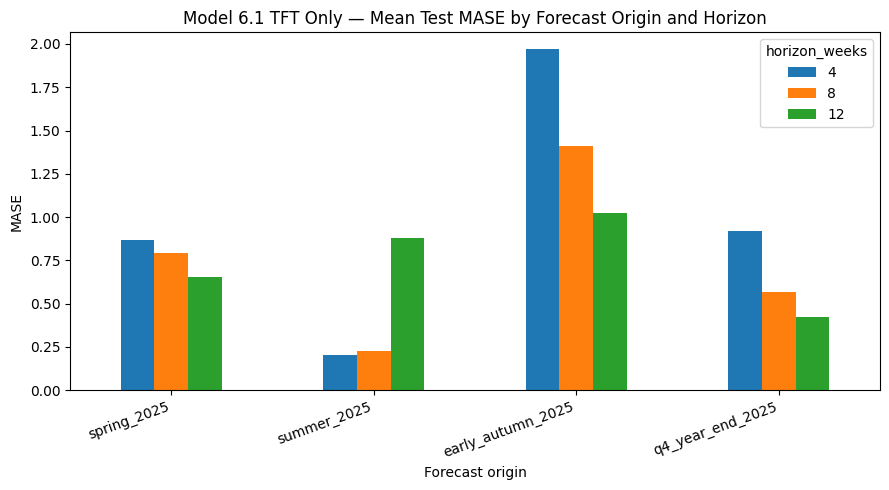

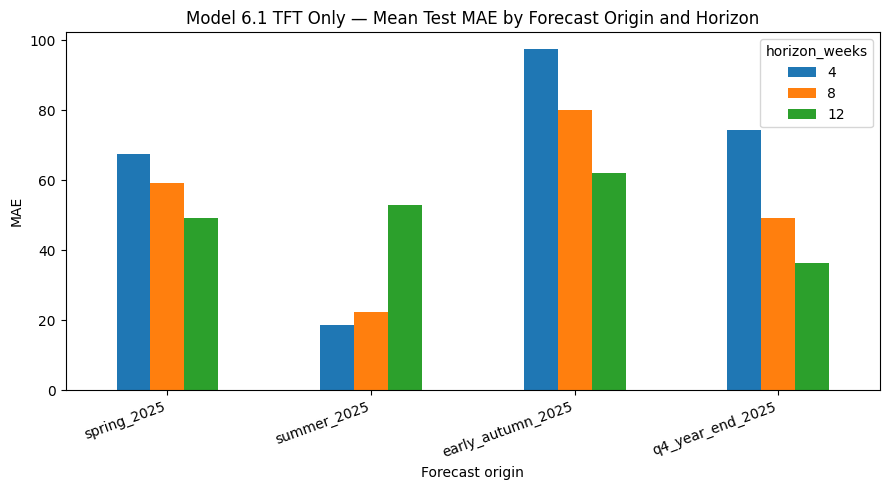

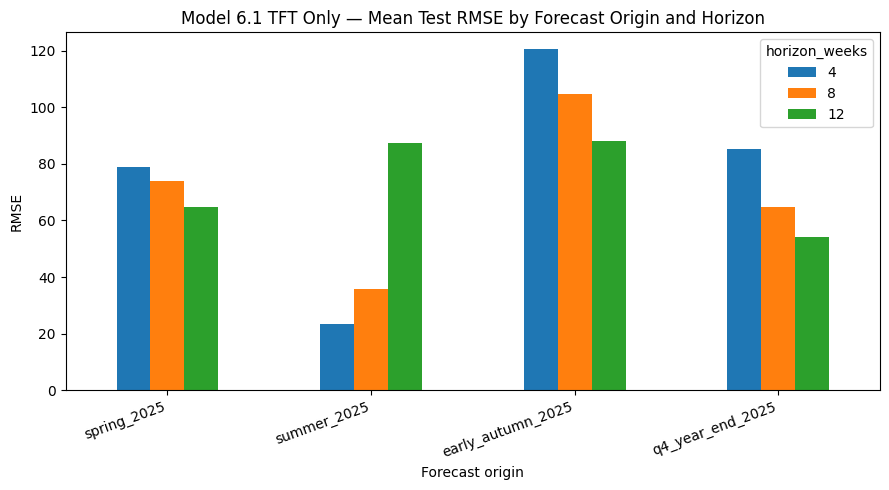

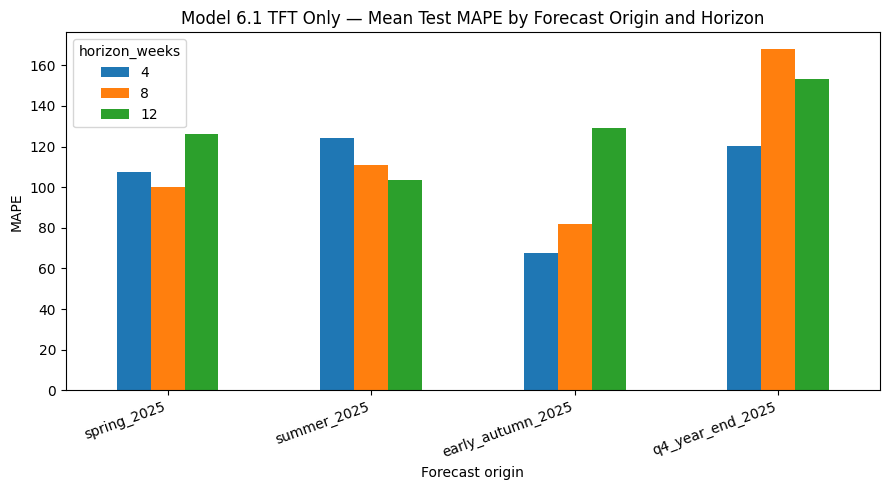

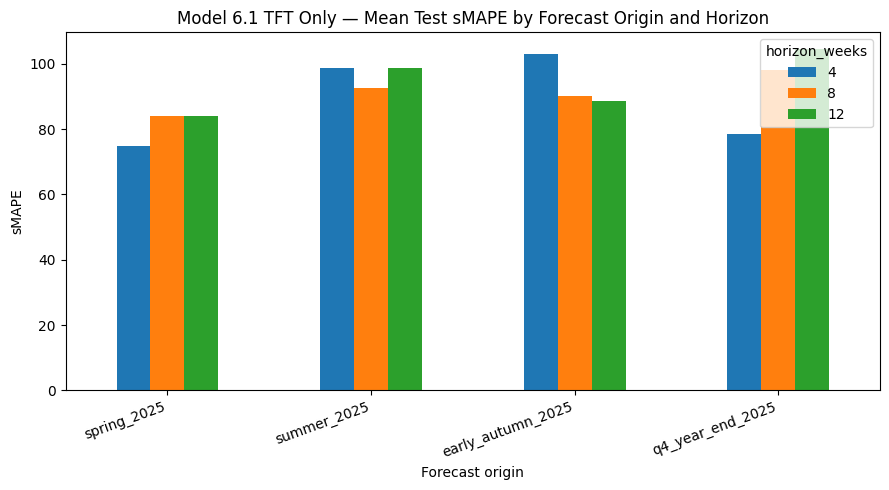

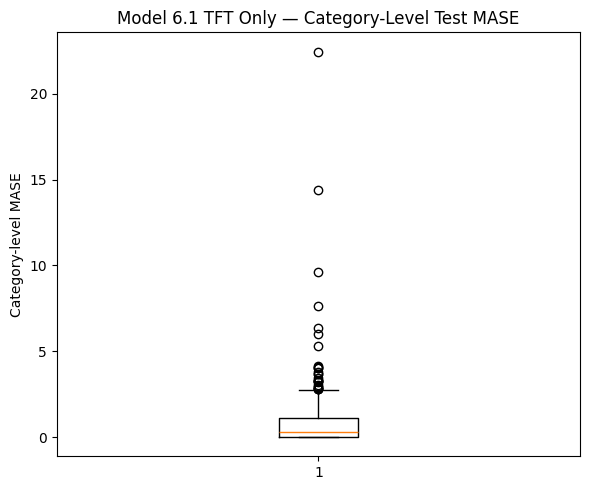

In [8]:
scenario_summary = (
    test_df.groupby(["scenario_id", "outer_origin_label", "horizon_weeks"], as_index=False)
    .agg(MAE=("MAE","mean"), RMSE=("RMSE","mean"), MAPE=("MAPE","mean"),
         sMAPE=("sMAPE","mean"), MASE=("MASE","mean"), median_MASE=("MASE","median"),
         valid_MASE_N=("MASE","count"))
)
overall_summary = pd.DataFrame([{
    "mean_MAE": test_df.MAE.mean(), "mean_RMSE": test_df.RMSE.mean(),
    "mean_MAPE": test_df.MAPE.mean(), "mean_sMAPE": test_df.sMAPE.mean(),
    "mean_MASE": test_df.MASE.mean(), "median_MASE": test_df.MASE.median(),
    "valid_MASE_evaluations": int(test_df.MASE.notna().sum()),
    "undefined_MASE_evaluations": int(test_df.MASE.isna().sum()),
    "total_evaluations": len(test_df),
}])
scenario_summary.to_csv(OUTPUT_DIR / "model_6_1_scenario_summary.csv", index=False)
overall_summary.to_csv(OUTPUT_DIR / "model_6_1_overall_summary.csv", index=False)
print("SCENARIO SUMMARY"); display(scenario_summary)
print("OVERALL SUMMARY"); display(overall_summary)

for metric in ["MASE", "MAE", "RMSE", "MAPE", "sMAPE"]:
    piv = scenario_summary.pivot(index="outer_origin_label", columns="horizon_weeks", values=metric).reindex(OUTER_ORIGINS.keys())
    ax = piv.plot(kind="bar", figsize=(9,5))
    ax.set_title(f"Model 6.1 TFT Only — Mean Test {metric} by Forecast Origin and Horizon")
    ax.set_ylabel(metric); ax.set_xlabel("Forecast origin")
    plt.xticks(rotation=20, ha="right"); plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"plot_test_{metric.lower()}_by_origin_horizon.png", dpi=160)
    plt.show()

plt.figure(figsize=(6,5))
plt.boxplot(test_df.MASE.dropna())
plt.ylabel("Category-level MASE")
plt.title("Model 6.1 TFT Only — Category-Level Test MASE")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "plot_category_mase_distribution.png", dpi=160)
plt.show()

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch

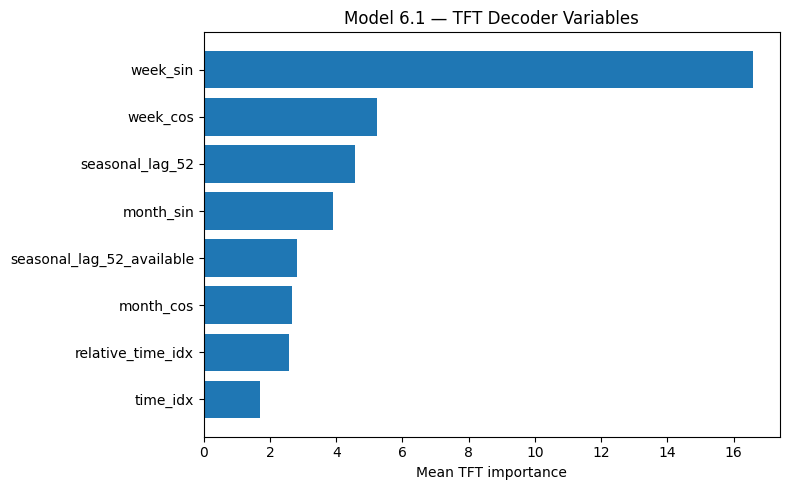

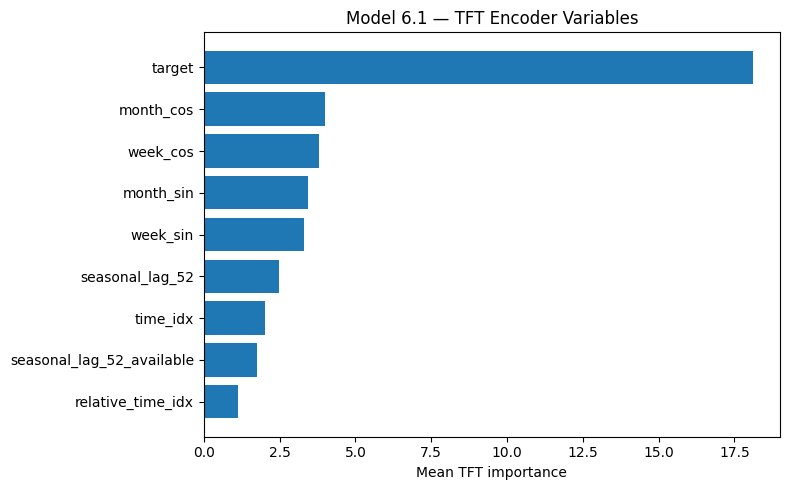

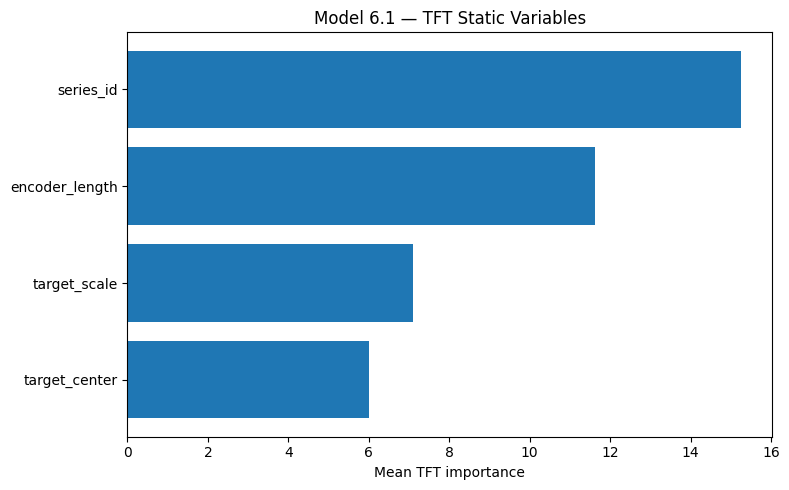

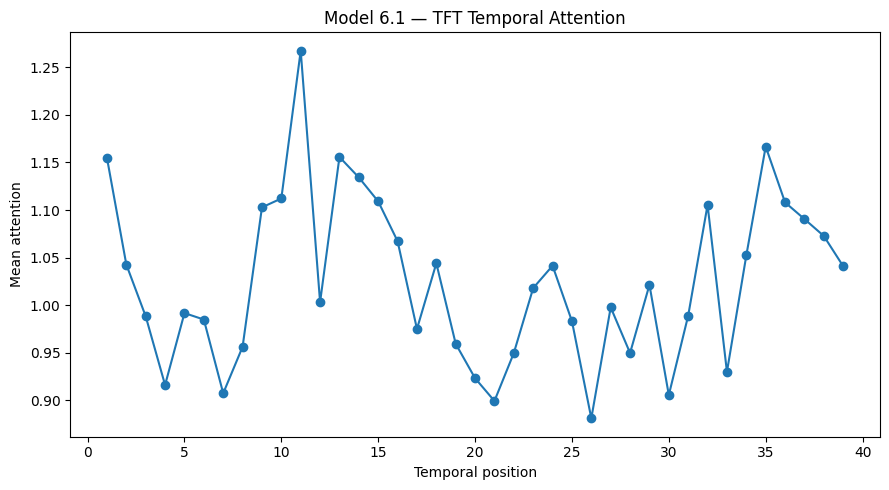

In [9]:
interpretation_rows = []
attention_rows = []

for origin_label, origin_s in OUTER_ORIGINS.items():
    origin = pd.Timestamp(origin_s)
    model = models_by_origin[origin_label]
    training = training_by_origin[origin_label]
    pred_frame = prediction_frame(origin, best_params["encoder_length"], MAX_HORIZON)
    pred_ds = TimeSeriesDataSet.from_dataset(training, pred_frame, predict=True, stop_randomization=True)
    loader = pred_ds.to_dataloader(train=False, batch_size=64, num_workers=0)

    try:
        raw = model.predict(loader, mode="raw", return_x=True)
        raw_output = raw.output if hasattr(raw, "output") else raw[0]
        interpretation = model.interpret_output(raw_output, reduction="sum")

        for key in ["static_variables", "encoder_variables", "decoder_variables"]:
            if key in interpretation:
                vals = interpretation[key]
                if torch.is_tensor(vals): vals = vals.detach().cpu().numpy()
                vals = np.asarray(vals).reshape(-1)
                names = {
                    "static_variables": list(model.static_variables),
                    "encoder_variables": list(model.encoder_variables),
                    "decoder_variables": list(model.decoder_variables),
                }[key]
                for name, val in zip(names, vals):
                    interpretation_rows.append({
                        "outer_origin_label": origin_label,
                        "importance_type": key,
                        "variable": name,
                        "importance": float(val),
                    })

        if "attention" in interpretation:
            att = interpretation["attention"]
            if torch.is_tensor(att): att = att.detach().cpu().numpy()
            att = np.asarray(att).reshape(-1)
            for pos, val in enumerate(att, 1):
                attention_rows.append({
                    "outer_origin_label": origin_label,
                    "relative_position": pos,
                    "attention": float(val),
                })
    except Exception as e:
        print(f"Native interpretation warning for {origin_label}: {e}")

native_importance_df = pd.DataFrame(interpretation_rows)
attention_df = pd.DataFrame(attention_rows)

if len(native_importance_df):
    native_importance_df.to_csv(OUTPUT_DIR / "model_6_1_tft_native_variable_importance.csv", index=False)
    plot_imp = native_importance_df.groupby(["importance_type", "variable"], as_index=False)["importance"].mean()
    for imp_type, g in plot_imp.groupby("importance_type"):
        g = g.sort_values("importance").tail(15)
        plt.figure(figsize=(8,5))
        plt.barh(g["variable"], g["importance"])
        plt.xlabel("Mean TFT importance")
        plt.title(f"Model 6.1 — TFT {imp_type.replace('_',' ').title()}")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / f"plot_tft_{imp_type}.png", dpi=160)
        plt.show()

if len(attention_df):
    attention_df.to_csv(OUTPUT_DIR / "model_6_1_tft_attention.csv", index=False)
    g = attention_df.groupby("relative_position", as_index=False)["attention"].mean()
    plt.figure(figsize=(9,5))
    plt.plot(g["relative_position"], g["attention"], marker="o")
    plt.xlabel("Temporal position")
    plt.ylabel("Mean attention")
    plt.title("Model 6.1 — TFT Temporal Attention")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "plot_tft_temporal_attention.png", dpi=160)
    plt.show()

SHAP surrogate fidelity R^2: 0.9873
SHAP surrogate fidelity MAE: 10.2191


,feature,mean_abs_shap
2,seasonal_lag_52,122.303124
1,category_code,12.450811
0,forecast_step,4.976147
4,week_cos,3.041142
3,week_sin,2.583664
6,month_cos,2.539195
5,month_sin,1.833386


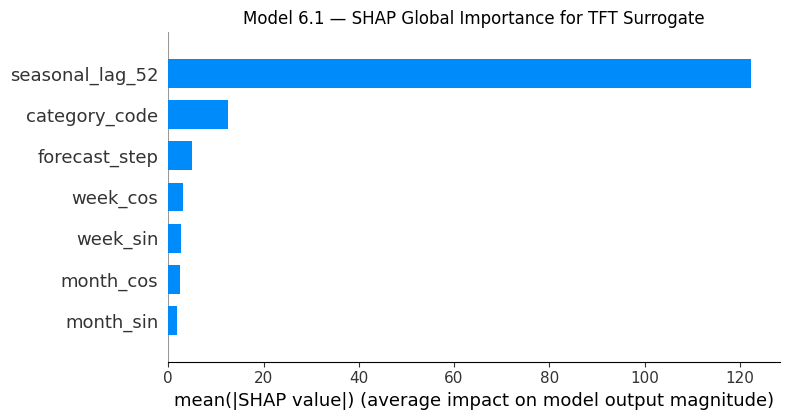

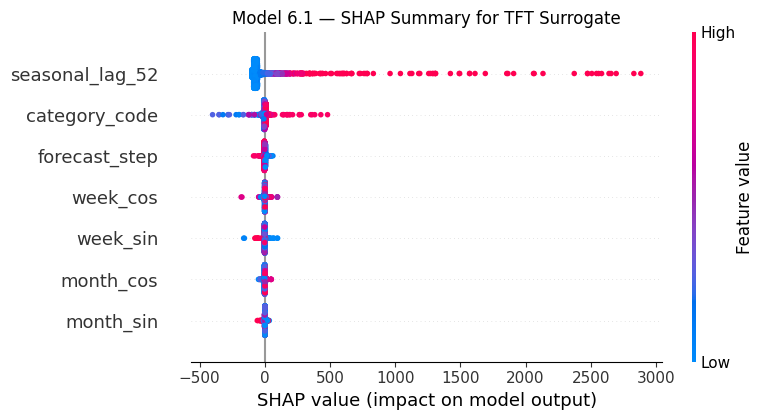

In [10]:
shap_df = forecasts_df.copy()
shap_df["month"] = pd.to_datetime(shap_df["week"]).dt.month.astype(float)
shap_df["quarter"] = pd.to_datetime(shap_df["week"]).dt.quarter.astype(float)
shap_df["week_of_year"] = pd.to_datetime(shap_df["week"]).dt.isocalendar().week.astype(float)
shap_df["week_sin"] = np.sin(2*np.pi*shap_df["week_of_year"]/52.0)
shap_df["week_cos"] = np.cos(2*np.pi*shap_df["week_of_year"]/52.0)
shap_df["month_sin"] = np.sin(2*np.pi*shap_df["month"]/12.0)
shap_df["month_cos"] = np.cos(2*np.pi*shap_df["month"]/12.0)
shap_df["category_code"] = pd.Categorical(shap_df["category"], categories=categories).codes.astype(float)

candidate_features = [
    "forecast_step", "category_code", "seasonal_lag_52",
    "month", "quarter", "week_of_year", "week_sin", "week_cos", "month_sin", "month_cos",
]
if best_params["feature_set"] == "cyclical":
    shap_features = ["forecast_step", "category_code", "seasonal_lag_52", "week_sin", "week_cos", "month_sin", "month_cos"]
else:
    shap_features = candidate_features

X = shap_df[shap_features].astype(float)
y_tft = shap_df["y_pred"].astype(float)

surrogate = ExtraTreesRegressor(
    n_estimators=500, min_samples_leaf=2, random_state=SEED, n_jobs=-1
)
surrogate.fit(X, y_tft)
surrogate_pred = surrogate.predict(X)
surrogate_r2 = r2_score(y_tft, surrogate_pred)
surrogate_mae = mae(y_tft, surrogate_pred)
print(f"SHAP surrogate fidelity R^2: {surrogate_r2:.4f}")
print(f"SHAP surrogate fidelity MAE: {surrogate_mae:.4f}")

fidelity_df = pd.DataFrame([{
    "surrogate_r2_to_tft_predictions": surrogate_r2,
    "surrogate_mae_to_tft_predictions": surrogate_mae,
    "n_explanation_rows": len(X),
}])
fidelity_df.to_csv(OUTPUT_DIR / "model_6_1_shap_surrogate_fidelity.csv", index=False)

explainer = shap.TreeExplainer(surrogate)
shap_values = explainer.shap_values(X)
if isinstance(shap_values, list):
    shap_values = shap_values[0]
shap_values = np.asarray(shap_values)

shap_importance = pd.DataFrame({
    "feature": shap_features,
    "mean_abs_shap": np.mean(np.abs(shap_values), axis=0),
}).sort_values("mean_abs_shap", ascending=False)
shap_importance.to_csv(OUTPUT_DIR / "model_6_1_shap_global_importance.csv", index=False)
display(shap_importance)

plt.figure(figsize=(9,6))
shap.summary_plot(shap_values, X, plot_type="bar", show=False)
plt.title("Model 6.1 — SHAP Global Importance for TFT Surrogate")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "plot_shap_global_bar.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(9,6))
shap.summary_plot(shap_values, X, show=False)
plt.title("Model 6.1 — SHAP Summary for TFT Surrogate")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "plot_shap_beeswarm.png", dpi=160, bbox_inches="tight")
plt.show()

In [11]:
best_trial_folds = trial_folds_df[trial_folds_df["trial"] == study.best_trial.number].copy()

audit_rows = []
earliest = pd.Timestamp(min(OUTER_ORIGINS.values()))
audit_rows.append(("outer_origins_match_common_framework", OUTER_ORIGINS == {
    "spring_2025":"2025-04-07", "summer_2025":"2025-07-07",
    "early_autumn_2025":"2025-09-08", "q4_year_end_2025":"2025-10-06"}))
audit_rows.append(("forecast_horizons_are_4_8_12", FORECAST_HORIZONS == [4,8,12]))
audit_rows.append(("all_architecture_tuning_validation_ends_before_first_outer_origin",
                   bool((pd.to_datetime(trial_folds_df["validation_end"]) < earliest).all())))
audit_rows.append(("architecture_selection_uses_multi_horizon_mase", True))
audit_rows.append(("exactly_30_optuna_trials", len(study.trials) == 30))
audit_rows.append(("no_google_trends_columns", not any("trend" in c.lower() or "google" in c.lower() for c in weekly.columns)))
audit_rows.append(("seasonal_lag_52_is_origin_available_for_h12", SEASONAL_PERIOD > MAX_HORIZON))
audit_rows.append(("outer_training_strictly_pre_origin",
                   bool((pd.to_datetime(meta_df["training_end"]) < pd.to_datetime(meta_df["outer_origin"])).all())))
audit_rows.append(("expected_480_category_horizon_evaluations", len(test_df) == len(categories)*len(OUTER_ORIGINS)*len(FORECAST_HORIZONS)))
audit_rows.append(("expected_1920_weekly_outer_forecasts", len(forecasts_df) == len(categories)*len(OUTER_ORIGINS)*MAX_HORIZON))
audit_rows.append(("all_predictions_nonnegative", bool((forecasts_df["y_pred"] >= 0).all())))
audit_rows.append(("mase_period_is_52", SEASONAL_PERIOD == 52))
audit_rows.append(("outer_prediction_frame_hides_actual_decoder_targets", True))

audit_df = pd.DataFrame(audit_rows, columns=["check", "passed"])
display(audit_df)
if not audit_df["passed"].all():
    raise AssertionError("One or more integrity checks failed.")
audit_df.to_csv(OUTPUT_DIR / "model_6_1_integrity_audit.csv", index=False)
print("Best architecture mean validation multi-horizon MASE:", study.best_value)
print("All integrity checks passed.")

,check,passed
0,outer_origins_match_common_framework,True
1,forecast_horizons_are_4_8_12,True
2,all_architecture_tuning_validation_ends_before...,True
3,architecture_selection_uses_multi_horizon_mase,True
4,exactly_30_optuna_trials,True
5,no_google_trends_columns,True
6,seasonal_lag_52_is_origin_available_for_h12,True
7,outer_training_strictly_pre_origin,True
8,expected_480_category_horizon_evaluations,True
9,expected_1920_weekly_outer_forecasts,True


Best architecture mean validation multi-horizon MASE: 3.1738197367141248
All integrity checks passed.


In [12]:
excel_path = OUTPUT_DIR / "model_6_1_tft_only_all_results.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    trials_df.to_excel(writer, sheet_name="Optuna_30_Trials", index=False)
    trial_folds_df.to_excel(writer, sheet_name="Optuna_Trial_Folds", index=False)
    pd.DataFrame([{**best_params, "final_epochs": BEST_EPOCHS,
                   "best_trial": study.best_trial.number,
                   "best_cv_multi_horizon_mase": study.best_value}]).to_excel(
        writer, sheet_name="Best_Architecture", index=False)
    scenarios.to_excel(writer, sheet_name="Scenarios", index=False)
    test_df.to_excel(writer, sheet_name="Outer_Test_Metrics", index=False)
    forecasts_df.to_excel(writer, sheet_name="Outer_Forecasts", index=False)
    scenario_summary.to_excel(writer, sheet_name="Scenario_Summary", index=False)
    overall_summary.to_excel(writer, sheet_name="Overall_Summary", index=False)
    meta_df.to_excel(writer, sheet_name="Outer_Model_Metadata", index=False)
    audit_df.to_excel(writer, sheet_name="Integrity_Audit", index=False)
    if len(native_importance_df):
        native_importance_df.to_excel(writer, sheet_name="TFT_Variable_Importance", index=False)
    if len(attention_df):
        attention_df.to_excel(writer, sheet_name="TFT_Attention", index=False)
    fidelity_df.to_excel(writer, sheet_name="SHAP_Surrogate_Fidelity", index=False)
    shap_importance.to_excel(writer, sheet_name="SHAP_Global_Importance", index=False)

print("Saved:", excel_path)
print("Best architecture JSON:", OUTPUT_DIR / "model_6_1_best_architecture.json")
print("Outer forecasts:", OUTPUT_DIR / "model_6_1_outer_forecasts.csv")
print("TFT interpretation and SHAP outputs saved to:", OUTPUT_DIR)

Saved: /content/drive/MyDrive/model_6_1_tft_only_outputs/model_6_1_tft_only_all_results.xlsx
Best architecture JSON: /content/drive/MyDrive/model_6_1_tft_only_outputs/model_6_1_best_architecture.json
Outer forecasts: /content/drive/MyDrive/model_6_1_tft_only_outputs/model_6_1_outer_forecasts.csv
TFT interpretation and SHAP outputs saved to: /content/drive/MyDrive/model_6_1_tft_only_outputs


In [13]:
audit_rows = []

for origin_label, origin_s in OUTER_ORIGINS.items():
    origin = pd.Timestamp(origin_s)

    future = weekly[
        (weekly["week"] >= origin) &
        (weekly["week"] < origin + pd.Timedelta(weeks=MAX_HORIZON))
    ].copy()

    future["lag_source_week"] = future["week"] - pd.Timedelta(weeks=52)

    audit_rows.append({
        "outer_origin": origin_label,
        "origin_date": origin,
        "max_forecast_week": future["week"].max(),
        "latest_lag_source_week": future["lag_source_week"].max(),
        "all_lag_sources_pre_origin":
            bool((future["lag_source_week"] < origin).all()),
        "n_decoder_rows": len(future)
    })

seasonal_lag_audit = pd.DataFrame(audit_rows)

display(seasonal_lag_audit)

assert seasonal_lag_audit["all_lag_sources_pre_origin"].all(), \
    "Seasonal lag-52 availability audit FAILED."

print("PASSED: all decoder seasonal_lag_52 values originate before forecast origin.")

,outer_origin,origin_date,max_forecast_week,latest_lag_source_week,all_lag_sources_pre_origin,n_decoder_rows
0,spring_2025,2025-04-07,2025-06-23,2024-06-24,True,480
1,summer_2025,2025-07-07,2025-09-22,2024-09-23,True,480
2,early_autumn_2025,2025-09-08,2025-11-24,2024-11-25,True,480
3,q4_year_end_2025,2025-10-06,2025-12-22,2024-12-23,True,480


PASSED: all decoder seasonal_lag_52 values originate before forecast origin.


X shape: (1920, 7)
SHAP shape: (1920, 7)
Features: ['forecast_step', 'category_code', 'seasonal_lag_52', 'week_sin', 'week_cos', 'month_sin', 'month_cos']


<Figure size 800x600 with 0 Axes>

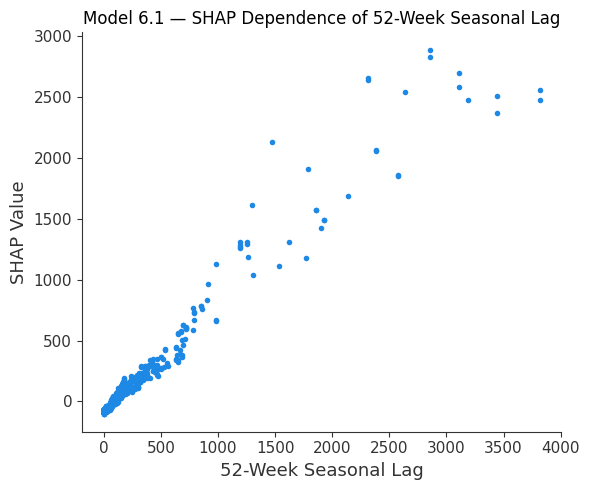


SHAP GLOBAL IMPORTANCE


,feature,mean_abs_shap,relative_importance_pct
0,seasonal_lag_52,122.303124,81.683825
1,category_code,12.450811,8.315649
2,forecast_step,4.976147,3.323470
3,week_cos,3.041142,2.031118
4,week_sin,2.583664,1.725578
5,month_cos,2.539195,1.695878
6,month_sin,1.833386,1.224482



Representative forecast
-----------------------
Row: 772
Category: ΠΟΡΤΟΦΟΛΙ ΑΝΔΡΙΚΟ
Week: 2025-08-04 00:00:00
Forecast step: 5
TFT prediction: 9.012172258460183e-11
Actual: 0.0
Seasonal lag 52: 11.0


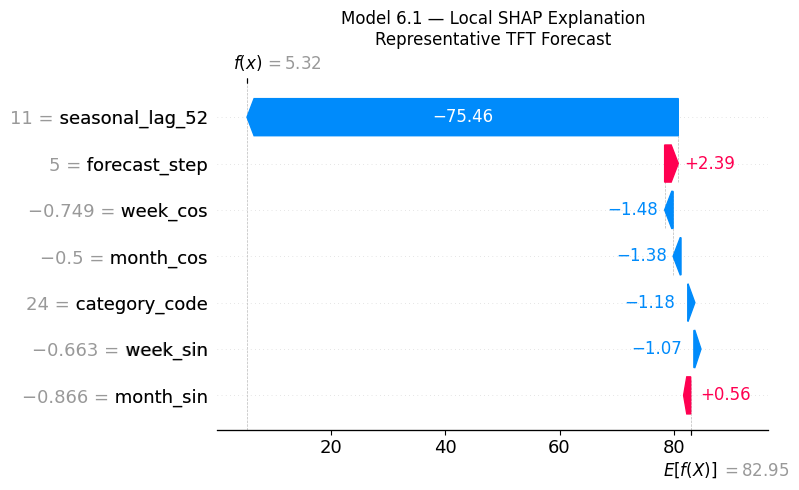


LOCAL SHAP CONTRIBUTIONS


,feature,feature_value,shap_value,abs_shap_value
0,seasonal_lag_52,11.000000,-75.461033,75.461033
1,forecast_step,5.000000,2.389177,2.389177
2,week_cos,-0.748511,-1.480544,1.480544
3,month_cos,-0.500000,-1.383887,1.383887
4,category_code,24.000000,-1.182510,1.182510
5,week_sin,-0.663123,-1.068043,1.068043
6,month_sin,-0.866025,0.556844,0.556844



MODEL 6.1 — EXTENDED SHAP INTERPRETABILITY COMPLETE
Most important feature: seasonal_lag_52
Mean |SHAP|: 122.3031
Relative importance: 81.68%

Saved:
 - plot_shap_dependence_seasonal_lag52.png
 - plot_shap_waterfall_representative.png
 - model_6_1_shap_importance_extended.csv
 - model_6_1_local_shap_representative.csv

Interpretation note: SHAP explains the Extra Trees surrogate fitted to reproduce TFT forecasts. It should therefore be interpreted together with the reported surrogate fidelity (R² and MAE), rather than as direct SHAP decomposition of the TFT neural network.


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

required_objects = ["X", "shap_values", "explainer", "surrogate"]

missing = [obj for obj in required_objects if obj not in globals()]
if missing:
    raise RuntimeError(
        f"Missing objects: {missing}. "
        "Run the existing SHAP cell immediately before this cell."
    )

sv = np.asarray(shap_values)

if sv.ndim == 3:
    sv = sv[..., 0]

assert sv.shape[0] == X.shape[0], "SHAP/X row mismatch."
assert sv.shape[1] == X.shape[1], "SHAP/X feature mismatch."

print("X shape:", X.shape)
print("SHAP shape:", sv.shape)
print("Features:", list(X.columns))

FEATURE = "seasonal_lag_52"

if FEATURE not in X.columns:
    raise ValueError(
        f"{FEATURE} not found. Available features: {list(X.columns)}"
    )

plt.figure(figsize=(8, 6))

shap.dependence_plot(
    FEATURE,
    sv,
    X,
    interaction_index=None,
    show=False
)

plt.title(
    "Model 6.1 — SHAP Dependence of 52-Week Seasonal Lag"
)
plt.xlabel("52-Week Seasonal Lag")
plt.ylabel("SHAP Value")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "plot_shap_dependence_seasonal_lag52.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

shap_importance_extended = pd.DataFrame({
    "feature": X.columns,
    "mean_abs_shap": np.mean(np.abs(sv), axis=0)
})

shap_importance_extended = (
    shap_importance_extended
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

total_importance = shap_importance_extended["mean_abs_shap"].sum()

shap_importance_extended["relative_importance_pct"] = (
    100
    * shap_importance_extended["mean_abs_shap"]
    / total_importance
)

print("\nSHAP GLOBAL IMPORTANCE")
display(shap_importance_extended)

shap_importance_extended.to_csv(
    OUTPUT_DIR / "model_6_1_shap_importance_extended.csv",
    index=False
)

median_prediction = shap_df["y_pred"].median()

example_idx = int(
    np.argmin(
        np.abs(
            shap_df["y_pred"].to_numpy(dtype=float)
            - median_prediction
        )
    )
)

print("\nRepresentative forecast")
print("-----------------------")
print("Row:", example_idx)
print("Category:", shap_df.iloc[example_idx]["category"])
print("Week:", shap_df.iloc[example_idx]["week"])
print("Forecast step:", shap_df.iloc[example_idx]["forecast_step"])
print("TFT prediction:", shap_df.iloc[example_idx]["y_pred"])
print("Actual:", shap_df.iloc[example_idx]["y_true"])
print(
    "Seasonal lag 52:",
    shap_df.iloc[example_idx]["seasonal_lag_52"]
)

expected_value = np.asarray(explainer.expected_value)

if expected_value.size == 1:
    base_value = float(expected_value.reshape(-1)[0])
else:
    base_value = float(expected_value[0])

local_explanation = shap.Explanation(
    values=sv[example_idx],
    base_values=base_value,
    data=X.iloc[example_idx].to_numpy(dtype=float),
    feature_names=list(X.columns)
)

shap.plots.waterfall(
    local_explanation,
    max_display=min(12, X.shape[1]),
    show=False
)

plt.title(
    "Model 6.1 — Local SHAP Explanation\n"
    "Representative TFT Forecast"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "plot_shap_waterfall_representative.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

local_shap_df = pd.DataFrame({
    "feature": X.columns,
    "feature_value": X.iloc[example_idx].to_numpy(dtype=float),
    "shap_value": sv[example_idx]
})

local_shap_df["abs_shap_value"] = np.abs(
    local_shap_df["shap_value"]
)

local_shap_df = (
    local_shap_df
    .sort_values("abs_shap_value", ascending=False)
    .reset_index(drop=True)
)

local_shap_df.to_csv(
    OUTPUT_DIR / "model_6_1_local_shap_representative.csv",
    index=False
)

print("\nLOCAL SHAP CONTRIBUTIONS")
display(local_shap_df)

top = shap_importance_extended.iloc[0]

print("\n" + "=" * 70)
print("MODEL 6.1 — EXTENDED SHAP INTERPRETABILITY COMPLETE")
print("=" * 70)

print(
    f"Most important feature: {top['feature']}"
)
print(
    f"Mean |SHAP|: {top['mean_abs_shap']:.4f}"
)
print(
    f"Relative importance: "
    f"{top['relative_importance_pct']:.2f}%"
)

print("\nSaved:")
print(" - plot_shap_dependence_seasonal_lag52.png")
print(" - plot_shap_waterfall_representative.png")
print(" - model_6_1_shap_importance_extended.csv")
print(" - model_6_1_local_shap_representative.csv")

print(
    "\nInterpretation note: SHAP explains the Extra Trees "
    "surrogate fitted to reproduce TFT forecasts. "
    "It should therefore be interpreted together with the "
    "reported surrogate fidelity (R² and MAE), rather than "
    "as direct SHAP decomposition of the TFT neural network."
)